# ДЗ 1. Многоклассовая классификация: ImageNette + ResNet-18

**Задача:** многоклассовая классификация (10 классов).

**Датасет:** [ImageNette](https://github.com/fastai/imagenette) — официальное подмножество ImageNet (10 классов, ~9.5 тыс. train / ~3.9 тыс. val). Разрешено условием ДЗ: *«ImageNet (можно использовать не весь список классов)»*. Ноутбук сам находит датасет: локально — `datasets/imagenette2` внутри проекта, на Kaggle — подключённый датасет (`/kaggle/input/*/imagenette2`) или скачивает его с S3 (в настройках ноутбука Kaggle должен быть включён **Internet**).

**Архитектура:** ResNet-18, собственная имплементация (BasicBlock, 4 стадии). Модель разделена на `feature_extractor` (свёрточные стадии) и `classifier` (линейная голова) — это задел под следующие ДЗ (SSL-предобучение и дистилляция).

**Метрики:** Precision / Recall / F1 по всем классам (macro) и по каждому классу, accuracy, confusion matrix.

## 0. Настройки

In [1]:
%matplotlib inline

import os
import random
import tarfile
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import classification_report, confusion_matrix
from torch.amp import GradScaler, autocast
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(42)

# Пути: на Kaggle всё пишется в /kaggle/working, локально — корень проекта
ON_KAGGLE = Path("/kaggle/input").exists()
ROOT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path(r"D:\FOR_STADY\магистратура\1_сем\image_generation")
DATA_DIR = ROOT_DIR / "datasets" / "imagenette2"  # датасет (в git не попадает)
RESULTS_DIR = ROOT_DIR / "results"                 # графики и отчёты (коммитятся)
CKPT_DIR = ROOT_DIR / "checkpoints"                # веса модели (не коммитятся)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Конфиг обучения (EPOCHS/NUM_WORKERS можно переопределить переменными окружения)
EPOCHS = int(os.environ.get("EPOCHS", "30"))
BATCH_SIZE = 32
LR = 1e-3
NUM_WORKERS = int(os.environ.get("NUM_WORKERS", "2"))

print(f"kaggle: {ON_KAGGLE} | device: {DEVICE} | epochs: {EPOCHS} | "
      f"batch: {BATCH_SIZE} | lr: {LR} | workers: {NUM_WORKERS}")

kaggle: True | device: cuda | epochs: 30 | batch: 32 | lr: 0.001 | workers: 2


## 1. Датасет ImageNette

In [2]:
IMAGENETTE_URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2.tgz"


def resolve_data_dir() -> Path:
    """Где брать датасет: локально datasets/imagenette2; на Kaggle — подключённый
    датасет /kaggle/input/*/imagenette2 (если есть), иначе /kaggle/working (скачаем)."""
    if DATA_DIR.exists():
        return DATA_DIR
    if ON_KAGGLE:
        for candidate in Path("/kaggle/input").glob("*/imagenette2"):
            if (candidate / "train").exists():
                return candidate
    return DATA_DIR


DATA_DIR = resolve_data_dir()

if not DATA_DIR.exists():  # датасета нигде нет — скачиваем и распаковываем (~1.5 GB)
    tgz_path = DATA_DIR.parent / "imagenette2.tgz"
    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
    print(f"Скачиваю ImageNette в {tgz_path}...")
    urllib.request.urlretrieve(IMAGENETTE_URL, tgz_path)
    with tarfile.open(tgz_path) as tar:
        tar.extractall(DATA_DIR.parent)
    tgz_path.unlink(missing_ok=True)
    print("Распаковано:", DATA_DIR)
else:
    print("Датасет:", DATA_DIR)

# Человекочитаемые имена классов (wnid -> название)
CLASS_NAMES = {
    "n01440764": "tench",
    "n02102040": "English springer",
    "n02979186": "cassette player",
    "n03000684": "chain saw",
    "n03028079": "church",
    "n03394916": "French horn",
    "n03417042": "garbage truck",
    "n03425413": "gas pump",
    "n03445777": "golf ball",
    "n03888257": "parachute",
}

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # статистики ImageNet

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
val_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder(DATA_DIR / "train", transform=train_tf)
val_ds = datasets.ImageFolder(DATA_DIR / "val", transform=val_tf)
class_names = [CLASS_NAMES[wnid] for wnid in train_ds.classes]

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False,
                        num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)

print(f"train: {len(train_ds)} | val: {len(val_ds)} | классов: {len(class_names)}")
print(class_names)

Скачиваю ImageNette в /kaggle/working/datasets/imagenette2.tgz...


/tmp/ipykernel_23/1038785035.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(DATA_DIR.parent)


Распаковано: /kaggle/working/datasets/imagenette2
train: 9469 | val: 3925 | классов: 10
['tench', 'English springer', 'cassette player', 'chain saw', 'church', 'French horn', 'garbage truck', 'gas pump', 'golf ball', 'parachute']


## 2. Архитектура ResNet-18

Классическая схема He et al., 2015: stem (7×7 conv, stride 2 + maxpool) → 4 стадии из BasicBlock'ов с каналами 64→128→256→512 (при переходе stride 2) → global average pooling → линейная голова. Residual-связь с 1×1-проекцией включается там, где меняются размерности.

In [3]:
class BasicBlock(nn.Module):
    """Базовый блок ResNet: два свёртки 3×3 + residual-связь."""
    expansion = 1

    def __init__(self, in_channels: int, out_channels: int, stride: int = 1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        # 1×1-проекция на residual-связи, если меняются размер карты или число каналов
        self.downsample = None
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return self.relu(out)


class ResNet(nn.Module):
    """ResNet для классификации.

    feature_extractor — свёрточные стадии до global average pooling (выход: вектор 512),
    classifier — линейная голова. Разделение пригодится в следующих ДЗ
    (SSL-предобучение экстрактора, дистилляция по скрытым состояниям).
    """

    def __init__(self, block: type, stage_blocks: list[int], num_classes: int = 10):
        super().__init__()
        self.in_channels = 64

        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )
        self.layer1 = self._make_stage(block, 64, stage_blocks[0], stride=1)
        self.layer2 = self._make_stage(block, 128, stage_blocks[1], stride=2)
        self.layer3 = self._make_stage(block, 256, stage_blocks[2], stride=2)
        self.layer4 = self._make_stage(block, 512, stage_blocks[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(512 * block.expansion, num_classes)

    def _make_stage(self, block, out_channels: int, num_blocks: int, stride: int):
        layers = [block(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        layers += [block(self.in_channels, out_channels, stride=1) for _ in range(num_blocks - 1)]
        return nn.Sequential(*layers)

    def feature_extractor(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.avgpool(x).flatten(1)  # (B, 512)

    def forward(self, x):
        return self.classifier(self.feature_extractor(x))


def resnet18(num_classes: int = 10) -> ResNet:
    """ResNet-18: 4 стадии по [2, 2, 2, 2] BasicBlock."""
    return ResNet(BasicBlock, [2, 2, 2, 2], num_classes)


model = resnet18(num_classes=len(class_names)).to(DEVICE)
print(f"ResNet-18: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} млн параметров")

with torch.no_grad():
    logits = model(torch.randn(2, 3, 224, 224, device=DEVICE))
print("проверка выхода:", tuple(logits.shape))

ResNet-18: 11.18 млн параметров
проверка выхода: (2, 10)


## 3. Обучение

AdamW + cosine-расписание, label smoothing 0.1, mixed precision (экономит память на 4 GB GPU). Каждый epoch — валидация, лучшая модель по val accuracy сохраняется в `checkpoints/best.pt`.

In [4]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)

# Прогрев LR + cosine: без прогрева AdamW на ResNet может разойтись (loss -> NaN)
WARMUP_EPOCHS = min(2, max(1, EPOCHS - 1))
scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[
        torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.01, total_iters=WARMUP_EPOCHS),
        torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS - WARMUP_EPOCHS),
    ],
    milestones=[WARMUP_EPOCHS],
)
scaler = GradScaler("cuda") if DEVICE.type == "cuda" else GradScaler("cpu", enabled=False)


def run_epoch(loader, train_mode: bool):
    model.train(train_mode)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train_mode):
        for images, targets in loader:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            with autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
                logits = model(images)
                loss = criterion(logits, targets)
            if train_mode:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)  # клиппинг градиентов против взрывов
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * targets.size(0)
            correct += (logits.argmax(1) == targets).sum().item()
            total += targets.size(0)
    return total_loss / total, correct / total


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, train_mode=True)
    val_loss, val_acc = run_epoch(val_loader, train_mode=False)
    scheduler.step()
    for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):
        history[key].append(value)
    marker = ""
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), CKPT_DIR / "best.pt")
        marker = "  <- best"
    print(f"epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f} acc {train_acc:.4f} "
          f"| val loss {val_loss:.4f} acc {val_acc:.4f}{marker}")

print(f"\nЛучший val accuracy: {best_val_acc:.4f}")

epoch 01/30 | train loss 1.9450 acc 0.3545 | val loss 1.6794 acc 0.5050  <- best
epoch 02/30 | train loss 1.7982 acc 0.4318 | val loss 1.5919 acc 0.5373  <- best
epoch 03/30 | train loss 1.5621 acc 0.5539 | val loss 1.5595 acc 0.5710  <- best
epoch 04/30 | train loss 1.3788 acc 0.6353 | val loss 1.3813 acc 0.6344  <- best
epoch 05/30 | train loss 1.2822 acc 0.6779 | val loss 1.2534 acc 0.6869  <- best
epoch 06/30 | train loss 1.2115 acc 0.7078 | val loss 1.2164 acc 0.7236  <- best
epoch 07/30 | train loss 1.1617 acc 0.7330 | val loss 1.2872 acc 0.6823
epoch 08/30 | train loss 1.1075 acc 0.7504 | val loss 1.1638 acc 0.7302  <- best
epoch 09/30 | train loss 1.0784 acc 0.7669 | val loss 1.1073 acc 0.7524  <- best
epoch 10/30 | train loss 1.0418 acc 0.7845 | val loss 1.1150 acc 0.7539  <- best
epoch 11/30 | train loss 1.0078 acc 0.7999 | val loss 1.0940 acc 0.7526
epoch 12/30 | train loss 0.9705 acc 0.8193 | val loss 1.0321 acc 0.7890  <- best
epoch 13/30 | train loss 0.9476 acc 0.8282 | v

## 4. Кривые обучения

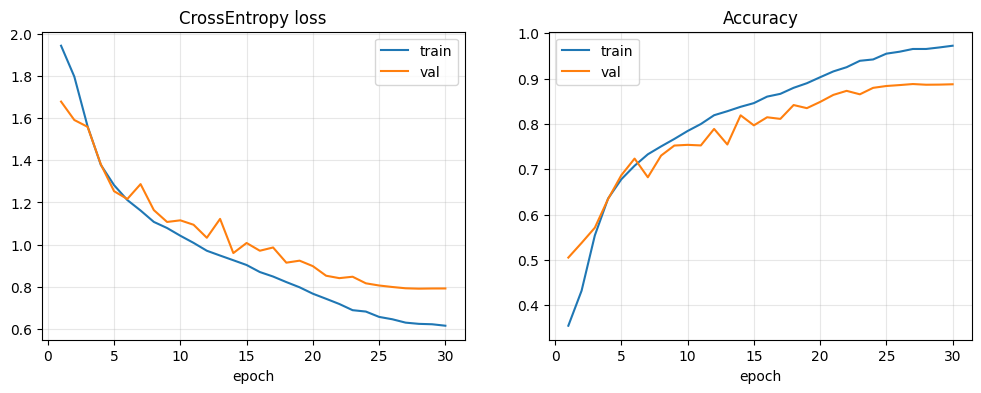

In [5]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], label="train")
axes[0].plot(epochs, history["val_loss"], label="val")
axes[0].set(title="CrossEntropy loss", xlabel="epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(epochs, history["train_acc"], label="train")
axes[1].plot(epochs, history["val_acc"], label="val")
axes[1].set(title="Accuracy", xlabel="epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.savefig(RESULTS_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Метрики на валидации

Precision / Recall / F1 по каждому классу и в среднем по всем классам (macro avg), accuracy и confusion matrix. Отчёт сохраняется в `results/classification_report.txt`.

                  precision    recall  f1-score   support

           tench     0.9406    0.9406    0.9406       387
English springer     0.9615    0.9494    0.9554       395
 cassette player     0.8312    0.9104    0.8690       357
       chain saw     0.7906    0.7824    0.7865       386
          church     0.9459    0.8973    0.9210       409
     French horn     0.8719    0.8985    0.8850       394
   garbage truck     0.8841    0.9023    0.8931       389
        gas pump     0.8506    0.8019    0.8256       419
       golf ball     0.8942    0.8897    0.8920       399
       parachute     0.9107    0.9154    0.9130       390

        accuracy                         0.8882      3925
       macro avg     0.8881    0.8888    0.8881      3925
    weighted avg     0.8888    0.8882    0.8881      3925



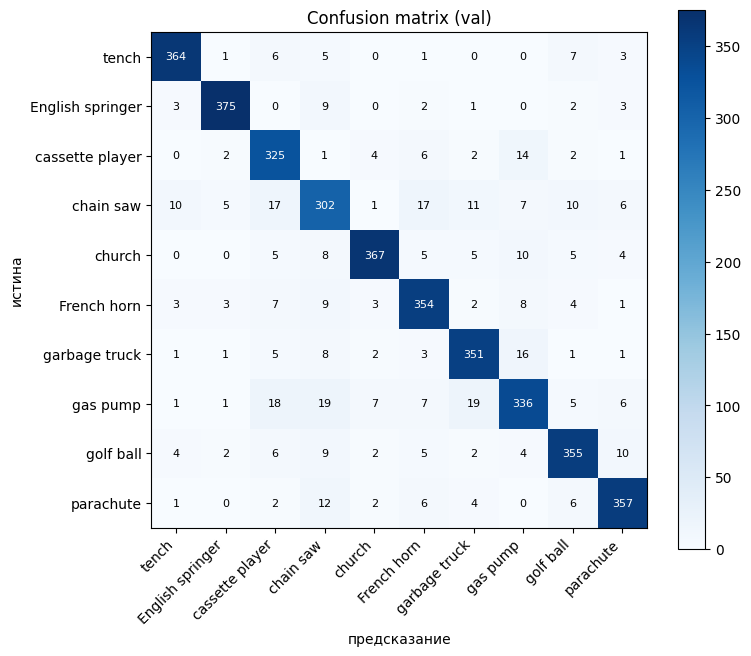

In [6]:
model.load_state_dict(torch.load(CKPT_DIR / "best.pt", weights_only=True))
model.eval()

all_preds, all_targets = [], []
with torch.no_grad():
    for images, targets in val_loader:
        logits = model(images.to(DEVICE))
        all_preds.extend(logits.argmax(1).cpu().tolist())
        all_targets.extend(targets.tolist())

report = classification_report(all_targets, all_preds, target_names=class_names, digits=4)
print(report)
with open(RESULTS_DIR / "classification_report.txt", "w", encoding="utf-8") as f:
    f.write(report)

cm = confusion_matrix(all_targets, all_preds)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(class_names)), class_names, rotation=45, ha="right")
ax.set_yticks(range(len(class_names)), class_names)
for i in range(len(class_names)):
    for j in range(len(class_names)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set(title="Confusion matrix (val)", xlabel="предсказание", ylabel="истина")
fig.colorbar(im)
fig.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## Выводы

Модель ResNet-18, обученная с нуля, решает задачу 10-классовой классификации ImageNette. Кривые обучения, метрики по классам и итоговые цифры — в `README.md` и папке `results/`.